In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

SEED = 7                    
rng = np.random.default_rng(SEED)

SIGMA_R = 0.3                      
SIGMA_X = SIGMA_Y = 0.25     

rad, ang = np.sqrt(rng.random()), 2 * np.pi * rng.random()
TRUE_POS = np.array([rad * np.cos(ang), rad * np.sin(ang)])
print(f"True vehicle position = ({TRUE_POS[0]:.3f}, {TRUE_POS[1]:.3f}),  distance from origin = {rad:.3f}")

def landmarks(K):
    a = 2 * np.pi * np.arange(K) / K
    return np.column_stack([np.cos(a), np.sin(a)])

def measure(pos, lm, rng):
    d = np.linalg.norm(lm - pos, axis=1)
    r = d + SIGMA_R * rng.standard_normal(len(d))
    while np.any(r < 0):
        bad = r < 0
        r[bad] = d[bad] + SIGMA_R * rng.standard_normal(bad.sum())
    return r

def map_objective(px, py, lm, r):
    J = px**2 / SIGMA_X**2 + py**2 / SIGMA_Y**2
    for (lx, ly), ri in zip(lm, r):
        J = J + (ri - np.sqrt((px - lx)**2 + (py - ly)**2))**2 / SIGMA_R**2
    return J

True vehicle position = (0.631, -0.476),  distance from origin = 0.791


In [2]:
gx, gy = np.meshgrid(np.linspace(-2, 2, 401), np.linspace(-2, 2, 401))
cell_area = (gx[0, 1] - gx[0, 0]) * (gy[1, 0] - gy[0, 0])
results = {}

for K in [1, 2, 3, 4]:
    lm = landmarks(K)
    r = measure(TRUE_POS, lm, rng)
    J = map_objective(gx, gy, lm, r)

    i = np.unravel_index(np.argmin(J), J.shape)
    res = minimize(lambda p: map_objective(p[0], p[1], lm, r), [gx[i], gy[i]], method="Nelder-Mead",
                   options={"xatol": 1e-8, "fatol": 1e-10})
    est = res.x

    post = np.exp(-(J - J.min()) / 2); post /= post.sum()
    p_sorted = np.sort(post.ravel())[::-1]
    area95 = (np.searchsorted(np.cumsum(p_sorted), 0.95) + 1) * cell_area

    results[K] = dict(lm=lm, r=r, J=J, est=est, Jmin=res.fun, area95=area95,
                      err=np.linalg.norm(est - TRUE_POS), post=post)
    print(f"K = {K}: ranges = {np.round(r, 3)}, true distances = {np.round(np.linalg.norm(lm - TRUE_POS, axis=1), 3)}")
    print(f"       MAP estimate = ({est[0]:.3f}, {est[1]:.3f}),  error = {results[K]['err']:.3f},  "
          f"min J = {res.fun:.2f},  95% region area = {area95:.3f}\n")

K = 1: ranges = [0.52], true distances = [0.602]
       MAP estimate = (0.197, -0.000),  error = 0.644,  min J = 1.51,  95% region area = 0.816

K = 2: ranges = [0.335 1.563], true distances = [0.602 1.699]
       MAP estimate = (0.357, -0.000),  error = 0.549,  min J = 3.57,  95% region area = 0.681

K = 3: ranges = [0.304 1.773 1.599], true distances = [0.602 1.755 1.197]
       MAP estimate = (0.507, -0.048),  error = 0.446,  min J = 7.46,  95% region area = 0.608

K = 4: ranges = [0.454 1.419 1.846 0.928], true distances = [0.602 1.605 1.699 0.821]
       MAP estimate = (0.423, -0.148),  error = 0.389,  min J = 5.79,  95% region area = 0.516



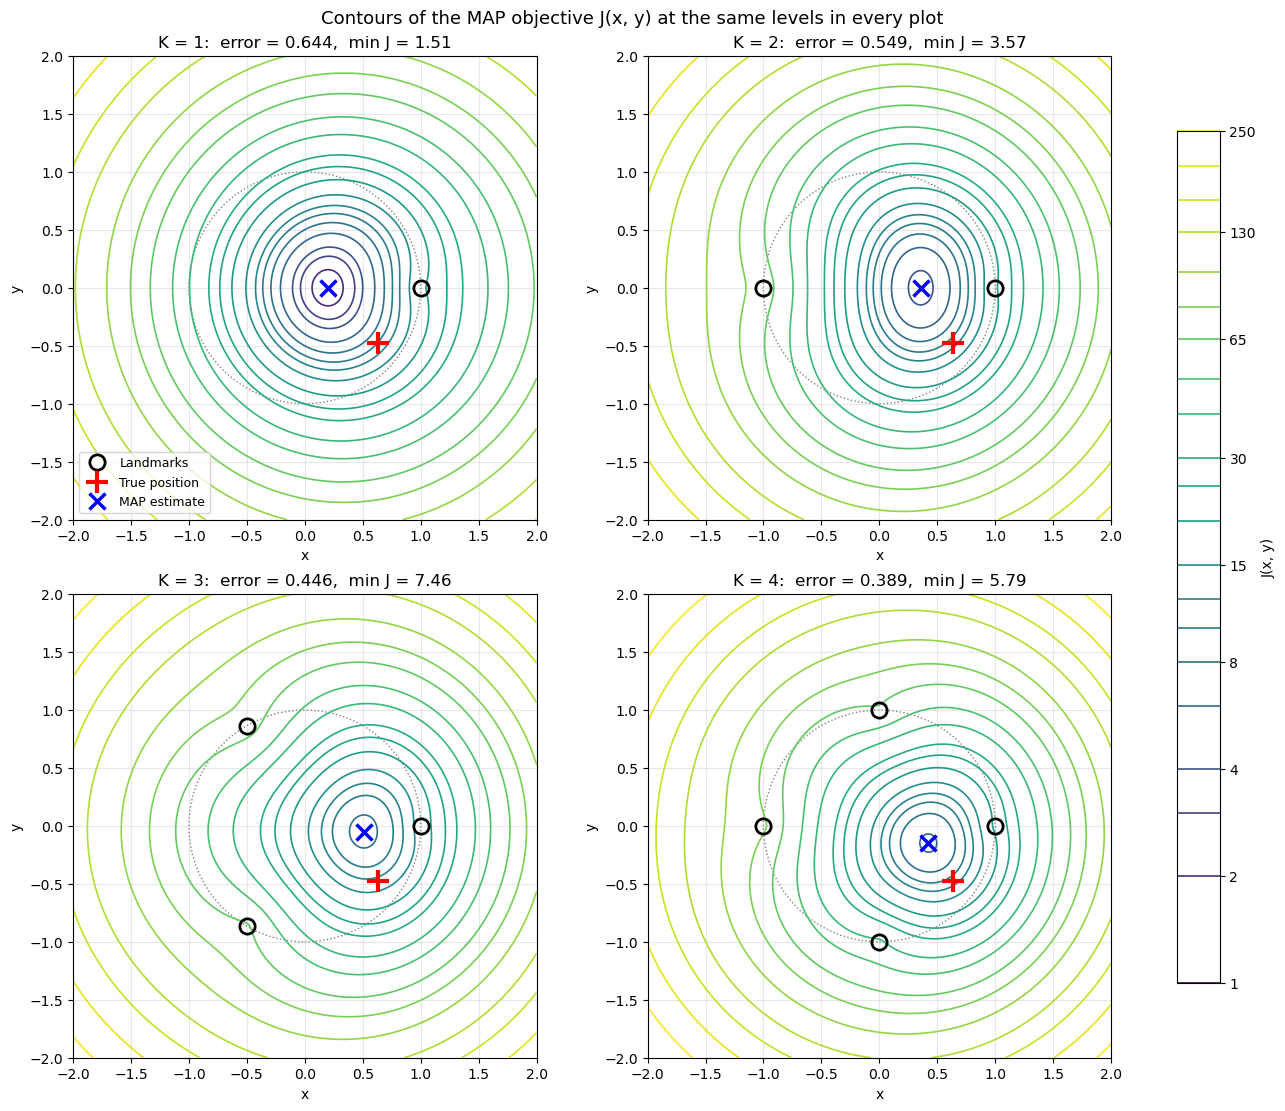

In [3]:
LEVELS = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 65, 80, 100, 130, 160, 200, 250]   # same values in every plot
norm = plt.matplotlib.colors.LogNorm(vmin=LEVELS[0], vmax=LEVELS[-1])
fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
for ax, K in zip(axes.ravel(), [1, 2, 3, 4]):
    R = results[K]
    cs = ax.contour(gx, gy, R["J"], levels=LEVELS, cmap="viridis", norm=norm, linewidths=1.2)
    ax.plot(*R["lm"].T, "o", ms=11, mfc="none", mec="k", mew=2, label="Landmarks")
    ax.plot(*TRUE_POS, "+", color="red", ms=16, mew=3, label="True position")
    ax.plot(*R["est"], "x", color="blue", ms=11, mew=2.5, label="MAP estimate")
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color="gray"))
    ax.set_title(f"K = {K}:  error = {R['err']:.3f},  min J = {R['Jmin']:.2f}")
    ax.set_xlim(-2, 2); ax.set_ylim(-2, 2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlabel("x"); ax.set_ylabel("y")
axes[0, 0].legend(loc="lower left", fontsize=9)
cbar = fig.colorbar(cs, ax=axes, shrink=0.85, label="J(x, y)")
cbar.set_ticks([1, 2, 4, 8, 15, 30, 65, 130, 250]); cbar.set_ticklabels(["1", "2", "4", "8", "15", "30", "65", "130", "250"])
fig.suptitle("Contours of the MAP objective J(x, y) at the same levels in every plot", fontsize=13)
plt.show()

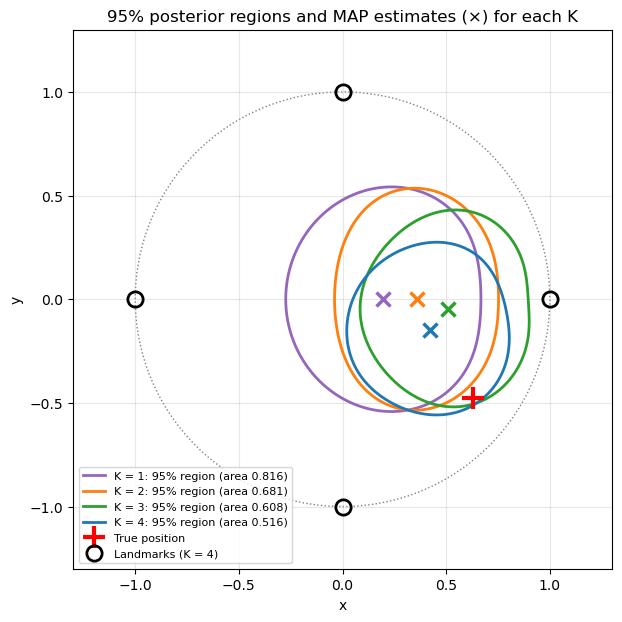

In [4]:
colors = {1: "tab:purple", 2: "tab:orange", 3: "tab:green", 4: "tab:blue"}
plt.figure(figsize=(7, 7))
for K in [1, 2, 3, 4]:
    R = results[K]
    p_sorted = np.sort(R["post"].ravel())[::-1]
    thr = p_sorted[np.searchsorted(np.cumsum(p_sorted), 0.95)]
    plt.contour(gx, gy, R["post"], levels=[thr], colors=colors[K], linewidths=2)
    plt.plot(*R["est"], "x", color=colors[K], ms=10, mew=2.5)
    plt.plot([], [], color=colors[K], lw=2, label=f"K = {K}: 95% region (area {R['area95']:.3f})")
plt.plot(*TRUE_POS, "+", color="red", ms=16, mew=3, label="True position")
plt.plot(*landmarks(4).T, "o", ms=11, mfc="none", mec="k", mew=2, label="Landmarks (K = 4)")
plt.gca().add_patch(plt.Circle((0, 0), 1, fill=False, ls=":", color="gray"))
plt.xlim(-1.3, 1.3); plt.ylim(-1.3, 1.3); plt.gca().set_aspect("equal"); plt.grid(alpha=0.3)
plt.xlabel("x"); plt.ylabel("y"); plt.title("95% posterior regions and MAP estimates (×) for each K")
plt.legend(fontsize=8, loc="lower left"); plt.show()

In [5]:
rng_rep = np.random.default_rng(2026)
n_rep = 500
cg_x, cg_y = np.meshgrid(np.linspace(-1.5, 1.5, 121), np.linspace(-1.5, 1.5, 121))
c_area = (cg_x[0, 1] - cg_x[0, 0]) ** 2
errs = {K: [] for K in [0, 1, 2, 3, 4]}
areas = {K: [] for K in [1, 2, 3, 4]}
for t in range(n_rep):
    rr, aa = np.sqrt(rng_rep.random()), 2 * np.pi * rng_rep.random()
    pos = np.array([rr * np.cos(aa), rr * np.sin(aa)])
    errs[0].append(np.linalg.norm(pos))                 
    for K in [1, 2, 3, 4]:
        lm = landmarks(K); r = measure(pos, lm, rng_rep)
        J = map_objective(cg_x, cg_y, lm, r)
        i = np.unravel_index(np.argmin(J), J.shape)
        est = minimize(lambda p: map_objective(p[0], p[1], lm, r), [cg_x[i], cg_y[i]], method="Nelder-Mead").x
        errs[K].append(np.linalg.norm(est - pos))
        post = np.exp(-(J - J.min()) / 2); post /= post.sum()
        areas[K].append((np.searchsorted(np.cumsum(np.sort(post.ravel())[::-1]), 0.95) + 1) * c_area)

print(f"{'K':>3s}{'mean error':>12s}{'median error':>14s}{'mean 95% area':>16s}")
for K in [0, 1, 2, 3, 4]:
    a = f"{np.mean(areas[K]):16.3f}" if K > 0 else f"{'(prior only)':>16s}"
    print(f"{K:3d}{np.mean(errs[K]):12.3f}{np.median(errs[K]):14.3f}{a}")

  K  mean error  median error   mean 95% area
  0       0.681         0.717    (prior only)
  1       0.566         0.576           0.929
  2       0.525         0.528           0.801
  3       0.387         0.379           0.617
  4       0.341         0.338           0.520
